# EDA dữ liệu cảm xúc VLSP — khảo sát trước tiền xử lý

Dữ liệu Base/Augmented được phân tích ở dạng gốc. Test chỉ dùng kiểm toán schema và giao tập, không dùng nhãn test để chọn quy tắc. Mọi tỷ lệ theo nhãn dưới đây chỉ dùng tập phát triển.

In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub>=0.3,<2', 'transformers>=4.40,<5', 'sentencepiece', 'pyvi==0.1.1', 'py_vncorenlp', 'gensim>=4.4,<5'])


0

In [ ]:
import re, unicodedata, json, hashlib
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
LABELS = [-1, 0, 1]
DATA_DIR = None
DATASET_HANDLE = 'anhphmduy/vlsp-sentiment-dataset/versions/5'
OUT = Path('vlsp_raw_eda'); OUT.mkdir(exist_ok=True)

In [ ]:
FILES = {
    "Base": ("vlsp_sentiment_train.csv",),
    "Augmented": ("vlsp_sentiment_train_augmented_v2.csv", "augmented_v2.csv"),
    "Test": ("vlsp_sentiment_test.csv",),
}

def locate_inputs(root):
    return {
        name: next((root / filename for filename in filenames if (root / filename).is_file()), None)
        for name, filenames in FILES.items()
    }

def resolve_inputs():
    if DATA_DIR is not None:
        root = Path(DATA_DIR).resolve()
    else:
        candidates = [
            Path("data"), Path("."),
            Path("/kaggle/input/vlsp-sentiment-dataset"),
            Path("/kaggle/input/datasets/anhphmduy/vlsp-sentiment-dataset"),
        ]
        root = next((p for p in candidates if all(locate_inputs(p).values())), None)
        if root is None:
            import kagglehub
            root = Path(kagglehub.dataset_download(DATASET_HANDLE))
            root = next(
                (p.parent for p in sorted(root.rglob(FILES["Base"][0]))
                 if all(locate_inputs(p.parent).values())),
                root,
            )
        root = root.resolve()
    paths = locate_inputs(root)
    missing = ["/".join(FILES[name]) for name, path in paths.items() if path is None]
    if missing:
        raise FileNotFoundError(f"Thiếu dữ liệu VLSP tại {root}: {', '.join(missing)}")
    return root, paths

def read_vlsp(path, split):
    for delimiter in ("\t", ","):
        header = pd.read_csv(path, sep=delimiter, encoding="utf-8-sig", nrows=0)
        if {"Class", "Data"}.issubset(header.columns.str.strip()):
            break
    else:
        raise ValueError(f"{path.name} cần hai cột Class và Data, phân tách bằng tab hoặc dấu phẩy.")
    frame = pd.read_csv(path, sep=delimiter, encoding="utf-8-sig", keep_default_na=False, dtype=str)
    frame.columns = frame.columns.str.strip()
    frame = frame[["Class", "Data"]].copy()
    labels = pd.to_numeric(frame["Class"], errors="coerce")
    invalid = ~labels.isin(LABELS)
    if frame.empty or invalid.any():
        raise ValueError(f"{path.name}: {int(invalid.sum())} nhãn sai hoặc tập rỗng.")
    frame["label"] = labels.astype(int)
    frame = frame.rename(columns={"Data": "text"})
    frame["row"] = np.arange(len(frame))
    frame["sample_id"] = split.lower() + "-" + frame["row"].astype(str)
    return frame[["sample_id", "row", "label", "text"]]

data_root, paths = resolve_inputs()
raw = {name: read_vlsp(path, name) for name, path in paths.items()}
print({name: len(frame) for name, frame in raw.items()})

Using Colab cache for faster access to the 'vlsp-sentiment-dataset' dataset.
{'Base': 5100, 'Augmented': 10149, 'Test': 1050}


## Phân bố, độ dài và chất lượng dữ liệu gốc

Tỷ lệ theo lớp dùng Base và Augmented. Giao test chỉ dựa trên văn bản, không dùng nhãn test.

label,-1,0,1
dataset,,,
Augmented,3385,3387,3377
Base,1700,1700,1700


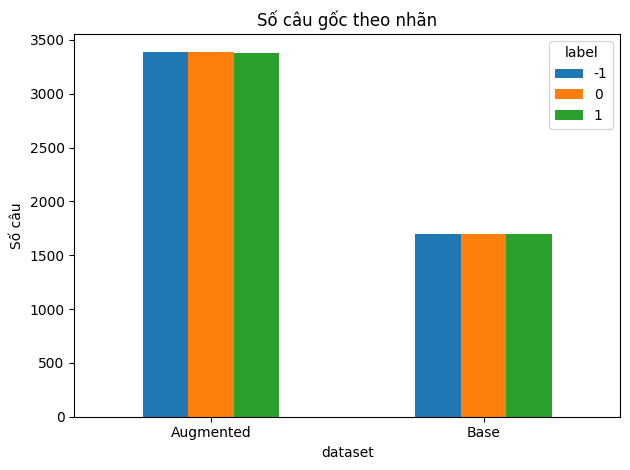

chars   words
dataset   label                      
Augmented -1    0.50     79.0    18.0
                0.90    240.0    54.0
                0.95    346.2    76.0
                0.99    596.6   136.0
                1.00   1656.0   376.0
           0    0.50    105.0    24.0
                0.90    311.4    69.0
                0.95    421.7    95.0
                0.99    907.3   205.0
                1.00  13036.0  2923.0
           1    0.50     71.0    16.0
                0.90    222.0    49.0
                0.95    309.0    69.0
                0.99    605.0   141.0
                1.00   2970.0   667.0
Base      -1    0.50     77.0    17.0
                0.90    230.0    52.0
                0.95    340.1    75.0
                0.99    558.1   133.0
                1.00   1532.0   356.0
           0    0.50    102.0    24.0
                0.90    306.1    68.0
                0.95    416.1    92.0
                0.99    957.2   220.0
                1.00  13164.0  2885.0
           1    0.50     69.0    16.0
                0.90    218.2    48.0
                0.95    298.0    67.0
                0.99    594.1   135.0
                1.00   2753.0   631.0

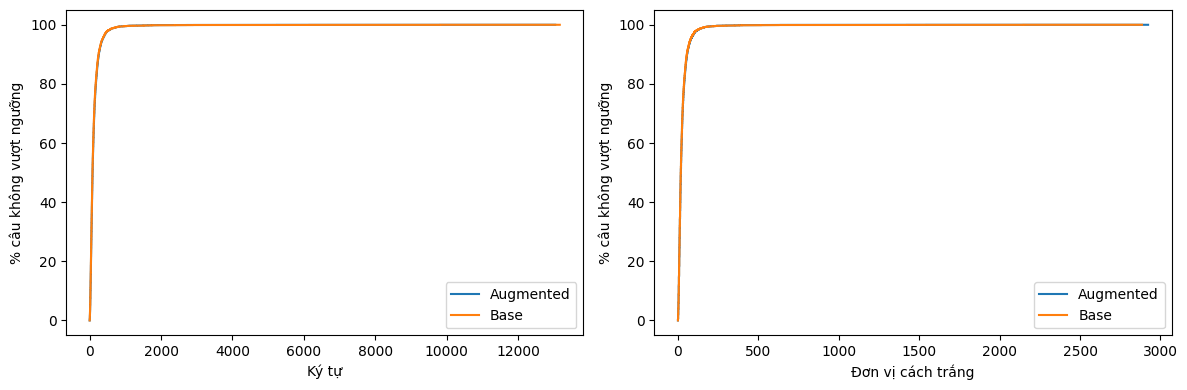

In [ ]:
dev = pd.concat([raw['Base'].assign(dataset='Base'), raw['Augmented'].assign(dataset='Augmented')], ignore_index=True)
counts = dev.groupby(['dataset','label']).size().unstack(fill_value=0).reindex(columns=LABELS,fill_value=0)
display(counts)
counts.to_csv(OUT/'label_counts.csv')
counts.plot.bar(rot=0, title='Số câu gốc theo nhãn', ylabel='Số câu'); plt.tight_layout(); plt.savefig(OUT/'labels.png'); plt.show()
lengths = dev.assign(chars=dev.text.str.len(), words=dev.text.str.split().str.len())
display(lengths.groupby(['dataset','label'])[['chars','words']].quantile([.5,.9,.95,.99,1]).round(1))
fig, axes=plt.subplots(1,2,figsize=(12,4))
for name, part in lengths.groupby('dataset'):
 for ax,col in zip(axes,['chars','words']):
  v=np.sort(part[col]); ax.step(v,100*np.arange(1,len(v)+1)/len(v),label=name)
for ax,col in zip(axes,['Ký tự','Đơn vị cách trắng']): ax.set(xlabel=col,ylabel='% câu không vượt ngưỡng'); ax.legend()
fig.tight_layout(); fig.savefig(OUT/'lengths.png'); plt.show()

,dataset,rows,blank,duplicate_extras,conflicting_keys,overlap_test
0,Base,5100,0,48,0.0,23.0
1,Augmented,10149,0,161,1.0,33.0
2,Test,1050,0,0,NaN,NaN


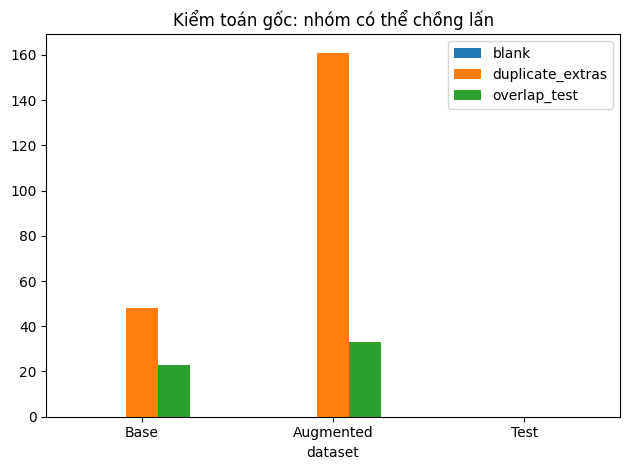

In [ ]:
def raw_key(text): return ' '.join(unicodedata.normalize('NFC',text).casefold().split())
keys={name:frame.text.map(raw_key) for name,frame in raw.items()}
audit=[]
for name,frame in raw.items():
 key=keys[name]; nonblank=key.ne('')
 conflicts=pd.DataFrame({'key':key,'label':frame.label}).loc[nonblank].groupby('key').label.nunique().gt(1).sum() if name!='Test' else None
 audit.append(dict(dataset=name,rows=len(frame),blank=int((~nonblank).sum()),duplicate_extras=int(key[nonblank].duplicated().sum()),conflicting_keys=conflicts,overlap_test=int((nonblank & key.isin(keys['Test'])).sum()) if name!='Test' else None))
audit=pd.DataFrame(audit); display(audit); audit.to_csv(OUT/'raw_audit.csv',index=False)
audit.set_index('dataset')[['blank','duplicate_extras','overlap_test']].plot.bar(rot=0,title='Kiểm toán gốc: nhóm có thể chồng lấn'); plt.tight_layout(); plt.savefig(OUT/'audit.png'); plt.show()

## Tín hiệu trong văn bản gốc

Tỷ lệ là phần trăm câu có ít nhất một tín hiệu; đồng xuất hiện không chứng minh ý nghĩa hay quan hệ nhân quả. Ví dụ lấy theo sample_id để có thể kiểm tra ngữ cảnh.

 phủ định — ví dụ gốc


/tmp/ipykernel_2498/2091302427.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask=dev.text.str.contains(pat,regex=True,na=False)


,dataset,sample_id,label,text
5101,Augmented,augmented-1,0,"ram lên nhiều làm gì, màn hình độ phân giải th..."
5110,Augmented,augmented-10,-1,"Cấu hình chỉ có ram 1gb 2gb, ssd 16gb, không h..."
15101,Augmented,augmented-10001,0,"có tiền thứ cứ làm cái 65 mà coi cho đã, hỏi l..."
15104,Augmented,augmented-10004,0,"mới đi xem thử sh01f với 304sh về, cam của sh0..."
15105,Augmented,augmented-10005,0,Mình chỉ sạc mỗi tháng một lần nên việc bật tắ...
15107,Augmented,augmented-10007,-1,có 1 triệu tôi cũng không made in china.
15108,Augmented,augmented-10008,0,bạn sai rồi nhé. tôi đã từng xài ip 3 đời..lúc...
15110,Augmented,augmented-10010,0,làm sao để mua được khi tôi ở đà nẵng đây. mà ...


/tmp/ipykernel_2498/2091302427.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask=dev.text.str.contains(pat,regex=True,na=False)


 teencode ứng viên — ví dụ gốc


,dataset,sample_id,label,text
7803,Augmented,augmented-2703,0,có rất nhiều lựa chọn. mặc dù tôi rất rất iu ip
5522,Augmented,augmented-422,1,"nhìn em iphone iu gì đâu á, mấy em còn lại khô..."
12002,Augmented,augmented-6902,1,"pin máy được nhà sx rất kỳ vọng , là ưu điểm m..."
13356,Augmented,augmented-8256,1,quá tuyệt vời.... điều mà tôi mong mỏi... tôi ...
15045,Augmented,augmented-9945,1,có nhìu bạn lả fan giống mình iu surface quá cơ!
10,Base,base-10,-1,"Mình cũng giật kinh khủng, cảm thấy hơi nản về..."
1001,Base,base-1001,-1,Bác nào đã lấy con A6 bên TCS mà ngoại tỉnh ko...
1002,Base,base-1002,-1,"Cái cảm biến chuyển đôngj kém ghê, quay tay lú..."


... (4 outputs left out)

,dataset,sample_id,label,text
1023,Base,base-1023,-1,Sau khi đọc hết 21 trang comment của mọi người...
1069,Base,base-1069,-1,ôi cái giá tiếp tục ngủ thôi :(
1078,Base,base-1078,-1,đẹp nhưng quá mắc. $1000 thì mua dc chứ giá kh...
1094,Base,base-1094,-1,"Độ nhạy tối đa 6400iso, 3 hình/giây. Công nghệ..."
110,Base,base-110,-1,Xấu hơn S6 active. nhưng nếu về VN mình chọn S...
1113,Base,base-1113,-1,"Giá khá mắc , tuy nhiên nếu bạn nào điều kiện ..."
1136,Base,base-1136,-1,"đeo thiết bị này cẩn thận nhé, vì rất dễ bị dị..."
1141,Base,base-1141,-1,Ai muốn mua cây bút chì chỉ với 99$? :))


 emoji — ví dụ gốc


,dataset,sample_id,label,text


,signal,dataset,label,count,total,percent
0,phủ định,Augmented,-1,1536,3385,45.376662
1,phủ định,Augmented,0,1608,3387,47.475642
2,phủ định,Augmented,1,994,3377,29.434409
3,phủ định,Base,-1,685,1700,40.294118
4,phủ định,Base,0,717,1700,42.176471
5,phủ định,Base,1,454,1700,26.705882
6,teencode ứng viên,Augmented,-1,0,3385,0.000000
7,teencode ứng viên,Augmented,0,1,3387,0.029525
8,teencode ứng viên,Augmented,1,4,3377,0.118448
9,teencode ứng viên,Base,-1,295,1700,17.352941


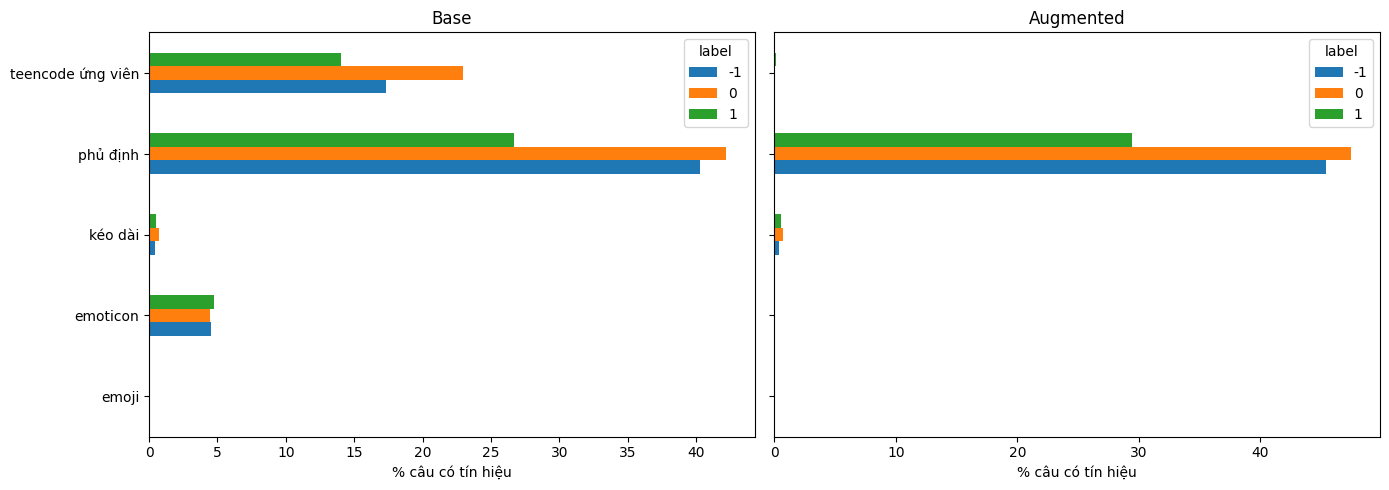

In [ ]:
patterns={'phủ định':r'(?i)(?<!\w)(không|chẳng|chưa|ko|hok|khg)(?!\w)', 'teencode ứng viên':r'(?i)(?<!\w)(ko|hok|khg|đc|dc|sp|đt|thik|iu|mik|vs|bthg|cx)(?!\w)', 'kéo dài':r'(?i)([^\W\d_])\1{2,}', 'emoticon':r'(?i)(?::[-]?[)(d]|\^\^|t\.t)', 'emoji':r'[\U0001F300-\U0001FAFF\u2764\uFE0F]'}
rows=[]
for name,pat in patterns.items():
 mask=dev.text.str.contains(pat,regex=True,na=False)
 for (dataset,label), group in dev.groupby(['dataset','label']):
  subset=mask.loc[group.index]; rows.append({'signal':name,'dataset':dataset,'label':label,'count':int(subset.sum()),'total':len(group),'percent':100*subset.mean()})
 print('\n',name,'— ví dụ gốc'); display(dev.loc[mask,['dataset','sample_id','label','text']].sort_values(['dataset','sample_id']).head(8))
signals=pd.DataFrame(rows); display(signals); signals.to_csv(OUT/'signal_rates.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,5),sharey=True)
for ax,name in zip(axes,['Base','Augmented']):
 signals[signals.dataset==name].pivot(index='signal',columns='label',values='percent').plot.barh(ax=ax); ax.set(title=name,xlabel='% câu có tín hiệu',ylabel='')
fig.tight_layout(); fig.savefig(OUT/'signals.png'); plt.show()

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
for name,frame in dev.groupby('dataset'):
 vectorizer=CountVectorizer(ngram_range=(1,2),binary=True,token_pattern=r'(?u)\b\w+\b',min_df=3,max_features=20000)
 matrix=vectorizer.fit_transform(frame.text); terms=vectorizer.get_feature_names_out()
 for label in LABELS:
  idx=np.flatnonzero(frame.label.to_numpy()==label); freq=np.asarray(matrix[idx].sum(axis=0)).ravel(); top=np.argsort(-freq,kind='stable')[:15]
  display(pd.DataFrame({'dataset':name,'label':label,'term':terms[top],'document_count':freq[top]}))

,dataset,label,term,document_count
0,Augmented,-1,không,1396
1,Augmented,-1,có,1012
2,Augmented,-1,là,844
3,Augmented,-1,thì,816
4,Augmented,-1,quá,659
5,Augmented,-1,và,659
6,Augmented,-1,này,586
7,Augmented,-1,mình,574
8,Augmented,-1,của,569
9,Augmented,-1,được,564


,dataset,label,term,document_count
0,Augmented,0,có,1485
1,Augmented,0,không,1459
2,Augmented,0,là,1179
3,Augmented,0,thì,1004
4,Augmented,0,bạn,843
5,Augmented,0,và,798
6,Augmented,0,mình,782
7,Augmented,0,được,782
8,Augmented,0,mua,767
9,Augmented,0,của,741


,dataset,label,term,document_count
0,Augmented,1,không,871
1,Augmented,1,có,846
2,Augmented,1,là,845
3,Augmented,1,và,800
4,Augmented,1,đẹp,786
5,Augmented,1,mình,740
6,Augmented,1,quá,726
7,Augmented,1,dùng,640
8,Augmented,1,rất,630
9,Augmented,1,này,571


,dataset,label,term,document_count
0,Base,-1,thì,450
1,Base,-1,có,421
2,Base,-1,là,420
3,Base,-1,không,418
4,Base,-1,mà,328
5,Base,-1,cái,310
6,Base,-1,quá,299
7,Base,-1,này,287
8,Base,-1,mua,271
9,Base,-1,của,248


,dataset,label,term,document_count
0,Base,0,có,628
1,Base,0,là,573
2,Base,0,thì,539
3,Base,0,không,416
4,Base,0,mà,392
5,Base,0,mua,378
6,Base,0,mình,353
7,Base,0,bạn,342
8,Base,0,cũng,327
9,Base,0,của,323


,dataset,label,term,document_count
0,Base,1,là,409
1,Base,1,quá,375
2,Base,1,đẹp,367
3,Base,1,có,355
4,Base,1,mình,315
5,Base,1,thì,296
6,Base,1,và,294
7,Base,1,dùng,288
8,Base,1,này,279
9,Base,1,mà,257


## Đối chiếu từng quy tắc trên cùng dữ liệu gốc


,dataset,rule,changed,percent,characters_removed,empty,collision_groups,conflicting_groups
0,Augmented,NFC+khoảng trắng,1,0.009853,3,0,0,0
1,Augmented,+chữ thường,4588,45.206424,3,0,51,1
2,Augmented,+teencode,6,0.059119,3,0,0,0
3,Augmented,+emoticon thành từ,1,0.009853,3,0,0,0
4,Augmented,+rút chữ kéo dài,55,0.541925,219,0,0,0
5,Augmented,+lọc ký hiệu,175,1.724308,207,0,0,0
6,Base,NFC+khoảng trắng,213,4.176471,2539,0,0,0
7,Base,+chữ thường,4292,84.156863,2539,0,10,0
8,Base,+teencode,1093,21.431373,2338,0,0,0
9,Base,+emoticon thành từ,434,8.509804,2481,0,0,0


,dataset,rule,sample_id,original,processed
0,Augmented,NFC+khoảng trắng,augmented-3403,Cảm ơn rất nhiều. Note 7 đã ra mắt và hy vọ...,Cảm ơn rất nhiều. Note 7 đã ra mắt và hy vọng ...
1,Augmented,+chữ thường,augmented-10,"Cấu hình chỉ có ram 1gb 2gb, ssd 16gb, không h...","cấu hình chỉ có ram 1gb 2gb, ssd 16gb, không h..."
2,Augmented,+chữ thường,augmented-100,Bạn dùng phần mềm gì trên 5s? Nếu tôi sử dụng ...,bạn dùng phần mềm gì trên 5s? nếu tôi sử dụng ...
3,Augmented,+chữ thường,augmented-10000,Đợi đến tháng 9 iPhone 7 ra mắt thì sẽ công bằ...,đợi đến tháng 9 iphone 7 ra mắt thì sẽ công bằ...
4,Augmented,+chữ thường,augmented-10005,Mình chỉ sạc mỗi tháng một lần nên việc bật tắ...,mình chỉ sạc mỗi tháng một lần nên việc bật tắ...
5,Augmented,+chữ thường,augmented-1001,"Cái này tương thích với qc 2.0, đã mua và zen2...","cái này tương thích với qc 2.0, đã mua và zen2..."
6,Augmented,+teencode,augmented-2703,có rất nhiều lựa chọn. mặc dù tôi rất rất iu ip,có rất nhiều lựa chọn. mặc dù tôi rất rất yêu ip
7,Augmented,+teencode,augmented-3403,Cảm ơn rất nhiều. Note 7 đã ra mắt và hy vọ...,Cảm ơn rất nhiều. Note 7 đã ra mắt và hy vọng ...
8,Augmented,+teencode,augmented-422,"nhìn em iphone iu gì đâu á, mấy em còn lại khô...","nhìn em iphone yêu gì đâu á, mấy em còn lại kh..."
9,Augmented,+teencode,augmented-6902,"pin máy được nhà sx rất kỳ vọng , là ưu điểm m...","pin máy được nhà sx rất kỳ vọng , là ưu điểm m..."


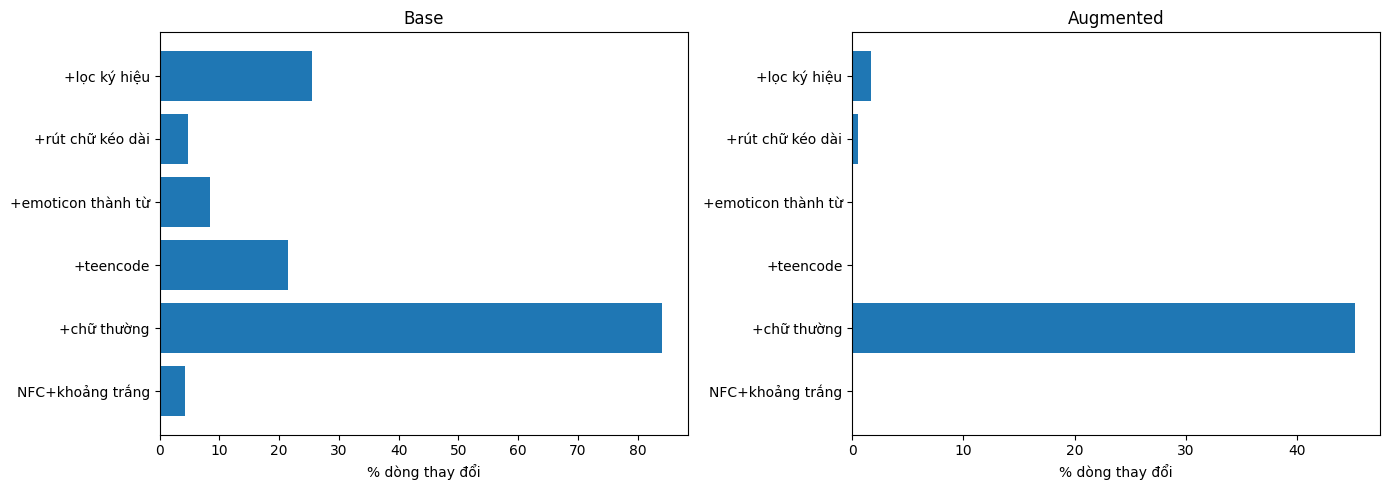

,term,dataset,sample_id,label,text
0,ko,Base,base-10,-1,"Mình cũng giật kinh khủng, cảm thấy hơi nản về..."
1,ko,Base,base-1001,-1,Bác nào đã lấy con A6 bên TCS mà ngoại tỉnh ko...
2,ko,Base,base-1002,-1,"Cái cảm biến chuyển đôngj kém ghê, quay tay lú..."
3,ko,Base,base-1003,-1,"em mua đc 2 ngày hỏng, shop ko thèm nói gì luô..."
4,ko,Base,base-1005,-1,vừa nhận cuộc gọi xác nhận của tcs. nhân viên ...
5,ko,Base,base-1006,-1,"em ở xa, gọi điện thì ko nghe máy hay nói thế ..."
6,hok,Base,base-1587,-1,mình chưa xài J7 nhưng mình đang xài cái sony ...
7,hok,Base,base-3206,1,"Đang xài con s4 active I9295 thấy ngon lành, r..."
8,hok,Base,base-350,-1,iPhone 7 như hình thì hok đáng để mua.xấu hơn ...
9,hok,Base,base-3822,0,"miếng dán da đó mỏng hay dày, nó có dễ bong ch..."


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Đã tạo ba biểu diễn riêng; chưa huấn luyện classifier và không dùng nhãn test.


In [ ]:
# Khảo sát các quy tắc độc lập; chưa sử dụng chúng để sửa dữ liệu nguồn.
import os, shutil, hashlib
from collections import Counter
from itertools import groupby
from functools import lru_cache
from sklearn.feature_extraction.text import TfidfVectorizer
from transformers import AutoTokenizer
from pyvi import ViTokenizer
import py_vncorenlp

def minimal(text):
    return ' '.join(unicodedata.normalize('NFC', text).split())

TEENCODE = {'ko':'không','hok':'không','khg':'không','đc':'được','dc':'được','sp':'sản phẩm','đt':'điện thoại','thik':'thích','iu':'yêu','mik':'mình','vs':'với','bthg':'bình thường','cx':'cũng'}
EMOTICONS = {'❤️':'yêu thích','👍':'tốt','😊':'vui vẻ','😍':'yêu thích','👎':'chê','😡':'tức giận','😭':'khóc','💔':'thất vọng',':)':'cười',':-)':'cười',':(':'buồn',':-(':'buồn',':d':'cười','^^':'vui','t.t':'khóc'}
teen_re = re.compile(r'\b(?:'+'|'.join(map(re.escape,TEENCODE))+r')\b',re.I)
emote_re = re.compile('|'.join(map(re.escape,sorted(EMOTICONS,key=len,reverse=True))),re.I)

def teen(text): return teen_re.sub(lambda m:TEENCODE[m[0].lower()],text)
def emote(text): return emote_re.sub(lambda m:' '+EMOTICONS[m[0].lower()]+' ',text)
def elong(text): return re.sub(r'([^\W\d_])\1{2,}',r'\1',text,flags=re.I)
def strip_symbols(text): return ' '.join(re.sub(r'[^\w\s.,!?]',' ',text).split())
transforms={'NFC+khoảng trắng':minimal,'+chữ thường':lambda x:minimal(x).lower(),'+teencode':lambda x:teen(minimal(x)), '+emoticon thành từ':lambda x:emote(minimal(x)), '+rút chữ kéo dài':lambda x:elong(minimal(x)), '+lọc ký hiệu':lambda x:strip_symbols(minimal(x))}
rule_rows=[]; examples=[]; collision_rows=[]
for dataset, frame in dev.groupby('dataset'):
    original=frame.text
    for name,fn in transforms.items():
        changed=original.map(fn)
        groups=pd.DataFrame({'raw':original,'processed':changed,'label':frame.label}).groupby('processed')
        rule_rows.append(dict(dataset=dataset,rule=name,changed=int(changed.ne(original).sum()),percent=100*changed.ne(original).mean(),characters_removed=int((original.str.len()-changed.str.len()).clip(lower=0).sum()),empty=int(changed.str.strip().eq('').sum()),collision_groups=int(groups.raw.nunique().gt(1).sum()),conflicting_groups=int(groups.label.nunique().gt(1).sum())))
        for idx in frame.loc[changed.ne(original)].sort_values('sample_id').head(5).index:
            examples.append(dict(dataset=dataset,rule=name,sample_id=dev.loc[idx,'sample_id'],original=original.loc[idx],processed=changed.loc[idx]))
        for processed,group in groups:
            if group.raw.nunique()>1:
                collision_rows.extend(dict(dataset=dataset,rule=name,original=r.raw,processed=processed,label=r.label) for r in group.itertuples())
rules=pd.DataFrame(rule_rows); display(rules); rules.to_csv(OUT/'rule_impacts.csv',index=False)
pd.DataFrame(examples).to_csv(OUT/'rule_examples.csv',index=False); display(pd.DataFrame(examples))
pd.DataFrame(collision_rows,columns=['dataset','rule','original','processed','label']).to_csv(OUT/'rule_collisions.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,dataset in zip(axes,['Base','Augmented']):
    part=rules[rules.dataset==dataset]; ax.barh(part.rule,part.percent); ax.set(title=dataset,xlabel='% dòng thay đổi')
fig.tight_layout(); fig.savefig(OUT/'rule-impacts.png',dpi=140); plt.show(); plt.close(fig)
# Từ viết tắt được đếm từng biểu thức, kèm ngữ cảnh để tránh suy nghĩa từ tần suất.
term_examples=[]
for term in TEENCODE:
    mask=dev.text.str.contains(r'(?i)(?<!\w)'+re.escape(term)+r'(?!\w)',regex=True)
    for row in dev.loc[mask].sort_values(['dataset','sample_id']).head(6).itertuples():
        term_examples.append(dict(term=term,dataset=row.dataset,sample_id=row.sample_id,label=row.label,text=row.text))
display(pd.DataFrame(term_examples)); pd.DataFrame(term_examples).to_csv(OUT/'teencode_contexts.csv',index=False)

# Giữ bản gốc và tạo các biểu diễn ứng viên riêng.
for name,frame in raw.items():
    frame['minimal']=frame.text.map(minimal)
    frame['tfidf_text']=frame.minimal.str.lower()
working=Path.cwd(); segdir=Path('vncorenlp').resolve(); segdir.mkdir(exist_ok=True)
try:
    if not (segdir/'VnCoreNLP-1.2.jar').exists():py_vncorenlp.download_model(save_dir=str(segdir))
    segmenter=py_vncorenlp.VnCoreNLP(annotators=['wseg'],save_dir=str(segdir))
finally:os.chdir(working)
@lru_cache(maxsize=None)
def segment(text):return ' '.join(segmenter.word_segment(text))
for dataset in ['Base','Augmented']:
    frame=raw[dataset]
    frame['cbow_text']=frame.minimal.str.lower().map(ViTokenizer.tokenize)
    frame['phobert_text']=frame.minimal.map(segment)
tokenizer=AutoTokenizer.from_pretrained('vinai/phobert-base-v2',use_fast=False)
print('Đã tạo ba biểu diễn riêng; chưa huấn luyện classifier và không dùng nhãn test.')


## Độ phủ TF-IDF, CBOW và mức cắt PhoBERT


In [ ]:
# TF-IDF: chỉ fit trên tập phát triển từng phiên bản, không dùng test.
WORD_PATTERN=r'(?u)\b\w+\b'
SYMBOL_PATTERN=r'(?u)(?::[-]?[)(d]|\^\^|t\.t|\b\w+\b)'
tfidf_rows=[]; coverage_rows=[]; dfs=[]
for dataset in ['Base','Augmented']:
    frame=raw[dataset]; texts=frame.tfidf_text
    for analyzer_name,pattern in [('word',WORD_PATTERN),('word+emoticon',SYMBOL_PATTERN)]:
        broad=TfidfVectorizer(token_pattern=pattern,ngram_range=(1,2),lowercase=False,dtype=np.float32)
        broad_matrix=broad.fit_transform(texts); total_occurrences=broad_matrix.getnnz()
        docfreq=np.asarray((broad_matrix>0).sum(axis=0)).ravel()
        dfs.extend(dict(dataset=dataset,analyzer=analyzer_name,df=int(value)) for value in docfreq)
        for min_df in [1,2,3,5]:
            for cap in [5000,10000,20000]:
                vectorizer=TfidfVectorizer(token_pattern=pattern,ngram_range=(1,2),lowercase=False,min_df=min_df,max_features=cap,sublinear_tf=True,dtype=np.float32)
                matrix=vectorizer.fit_transform(texts)
                empty=np.asarray(matrix.getnnz(axis=1)==0)
                tfidf_rows.append(dict(dataset=dataset,analyzer=analyzer_name,min_df=min_df,max_features=cap,features=matrix.shape[1],nnz=matrix.nnz,sparsity=1-matrix.nnz/(matrix.shape[0]*matrix.shape[1]),feature_occurrence_coverage=matrix.nnz/total_occurrences,empty_documents=int(empty.sum()),sparse_bytes=matrix.data.nbytes+matrix.indices.nbytes+matrix.indptr.nbytes,dense_batch128_bytes=128*matrix.shape[1]*4))
        # Mức thay đổi biểu diễn khi áp dụng từng quy tắc; cùng analyzer thực tế.
        for name,fn in transforms.items():
            values=frame.text.map(fn).str.lower()
            candidate=TfidfVectorizer(token_pattern=pattern,ngram_range=(1,2),max_features=5000,sublinear_tf=True,lowercase=False,dtype=np.float32)
            m=candidate.fit_transform(values)
            coverage_rows.append(dict(dataset=dataset,rule=name,analyzer=analyzer_name,features=m.shape[1],nnz=m.nnz,empty_documents=int((m.getnnz(axis=1)==0).sum())))
tfidf=pd.DataFrame(tfidf_rows); tfidf.to_csv(OUT/'tfidf_diagnostics.csv',index=False); display(tfidf)
pd.DataFrame(coverage_rows).to_csv(OUT/'tfidf_rule_comparison.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,dataset in zip(axes,['Base','Augmented']):
    for name,group in tfidf[(tfidf.dataset==dataset)&(tfidf.min_df==1)].groupby('analyzer'):
        ax.plot(group.max_features,100*group.feature_occurrence_coverage,marker='o',label=name)
    ax.set(title=dataset,xlabel='Giới hạn số đặc trưng',ylabel='% lượt đặc trưng-văn bản được giữ'); ax.legend()
fig.tight_layout(); fig.savefig(OUT/'tfidf-coverage.png',dpi=140); plt.show(); plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,dataset in zip(axes,['Base','Augmented']):
    values=pd.DataFrame(dfs); values=values[(values.dataset==dataset)&(values.analyzer=='word')].df.to_numpy(); values=np.sort(values)
    ax.step(values,100*np.arange(1,len(values)+1)/len(values)); ax.set(xscale='log',xlabel='Document frequency',ylabel='% đặc trưng có DF không vượt ngưỡng',title=dataset)
fig.tight_layout(); fig.savefig(OUT/'tfidf-df.png',dpi=140); plt.show(); plt.close(fig)

from gensim.models import KeyedVectors
vectors=KeyedVectors.load_word2vec_format(str(data_root/'vi-model-CBOW.bin'),binary=True)
sequence_rows=[]; oov_rows=[]; truncation_examples=[]; per_sample=[]
for dataset in ['Base','Augmented']:
    frame=raw[dataset]
    frequencies=Counter(word for text in frame.cbow_text for word in text.split())
    vocabulary={word for word,count in sorted(frequencies.items(),key=lambda p:(-p[1],p[0]))[:9998]}
    tokens=list(frequencies); total=sum(frequencies.values())
    covered=sum(count for word,count in frequencies.items() if word in vectors)
    oov_rows.extend(dict(dataset=dataset,word=word,count=count) for word,count in frequencies.most_common() if word not in vectors)
    print(dataset,'CBOW pretrained token coverage',covered/total,'type coverage',sum(w in vectors for w in tokens)/len(tokens))
    cbow_tokens=frame.cbow_text.str.split().tolist()
    bpe_tokens=[tokenizer.encode(text,add_special_tokens=True,truncation=False) for text in frame.phobert_text]
    for position,row in enumerate(frame.itertuples()):
        words=cbow_tokens[position]
        per_sample.append(dict(dataset=dataset,sample_id=row.sample_id,label=row.label,cbow_length=len(words),bpe_length=len(bpe_tokens[position]),pretrained_oov_fraction=sum(w not in vectors for w in words)/max(1,len(words)),vocab_unk_fraction=sum(w not in vocabulary for w in words)/max(1,len(words))))
    for embedder,sequences,limits in [('CBOW',cbow_tokens,[128,256,300,512]),('PhoBERT',bpe_tokens,[128,256])]:
        sizes=np.array([len(x) for x in sequences])
        for limit in limits:
            # BPE gồm special tokens: phần nội dung bị mất là length - limit.
            removed=np.maximum(0,sizes-limit)
            sequence_rows.append(dict(dataset=dataset,embedder=embedder,limit=limit,median=float(np.median(sizes)),p90=float(np.quantile(sizes,.9)),p95=float(np.quantile(sizes,.95)),p99=float(np.quantile(sizes,.99)),maximum=int(sizes.max()),truncated_documents=int((removed>0).sum()),truncated_percent=100*float((removed>0).mean()),tokens_removed=int(removed.sum()),tokens_removed_percent=100*float(removed.sum()/max(1,sizes.sum()))))
            if (embedder=='CBOW' and limit==300) or (embedder=='PhoBERT' and limit==256):
                candidates=frame.assign(size=sizes).loc[sizes>limit].sort_values('sample_id').head(4)
                for row in candidates.itertuples():
                    index=frame.index.get_loc(row.Index)
                    sequence=sequences[index]
                    lost=' '.join(sequence[limit:]) if embedder=='CBOW' else tokenizer.decode(sequence[limit-1:-1])
                    truncation_examples.append(dict(dataset=dataset,embedder=embedder,sample_id=row.sample_id,text=row.text,length=row.size,lost_content=lost))
sequence=pd.DataFrame(sequence_rows); display(sequence); sequence.to_csv(OUT/'sequence_limits.csv',index=False)
samples=pd.DataFrame(per_sample); samples.to_csv(OUT/'sample_token_diagnostics.csv',index=False)
oov=pd.DataFrame(oov_rows); oov.to_csv(OUT/'cbow_oov.csv',index=False); display(oov.groupby('dataset').head(20))
pd.DataFrame(truncation_examples,columns=['dataset','embedder','sample_id','text','length','lost_content']).to_csv(OUT/'truncation_examples.csv',index=False); display(pd.DataFrame(truncation_examples))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,column in zip(axes,['cbow_length','bpe_length']):
    for dataset,part in samples.groupby('dataset'):
        values=np.sort(part[column]); ax.step(values,100*np.arange(1,len(values)+1)/len(values),label=dataset)
    ax.axvline(300 if column=='cbow_length' else 256,color='red',linestyle='--'); ax.set(xlabel=column,ylabel='% câu không vượt ngưỡng'); ax.legend()
fig.tight_layout(); fig.savefig(OUT/'token-limits.png',dpi=140); plt.show(); plt.close(fig)
# Kiểm tra cả khác biệt coverage trước/sau từng quy tắc trên cùng câu.
coverage=[]
for dataset in ['Base','Augmented']:
    frame=raw[dataset]
    for rule,fn in transforms.items():
        texts=frame.text.map(fn)
        words=texts.str.lower().map(ViTokenizer.tokenize).str.split()
        counts=Counter(w for sentence in words for w in sentence)
        bpe_sizes=texts.map(segment).map(lambda s:len(tokenizer.encode(s,add_special_tokens=True,truncation=False)))
        coverage.append(dict(dataset=dataset,rule=rule,cbow_tokens=sum(counts.values()),cbow_oov_tokens=sum(c for w,c in counts.items() if w not in vectors),cbow_oov_types=sum(w not in vectors for w in counts),bpe_total=int(bpe_sizes.sum()),bpe_over256=int(bpe_sizes.gt(256).sum())))
coverage=pd.DataFrame(coverage); coverage.to_csv(OUT/'embedder_rule_comparison.csv',index=False); display(coverage)
print('Không có classifier được huấn luyện; thống kê embedder chỉ dùng Base/Augmented.')


## CBOW: Raincloud Plot

Nửa violin thể hiện mật độ, box thể hiện median/IQR, điểm jitter là mẫu hiển thị. Thống kê và mật độ dùng toàn bộ dữ liệu; tỷ lệ bằng 0 được ghi riêng.

Dữ liệu hình là toàn bộ Base/Augmented gốc đã khảo sát; vocabulary chẩn đoán fit trên từng tập phát triển gốc. Vocabulary dùng huấn luyện được fit lại sau audit/chia tập.


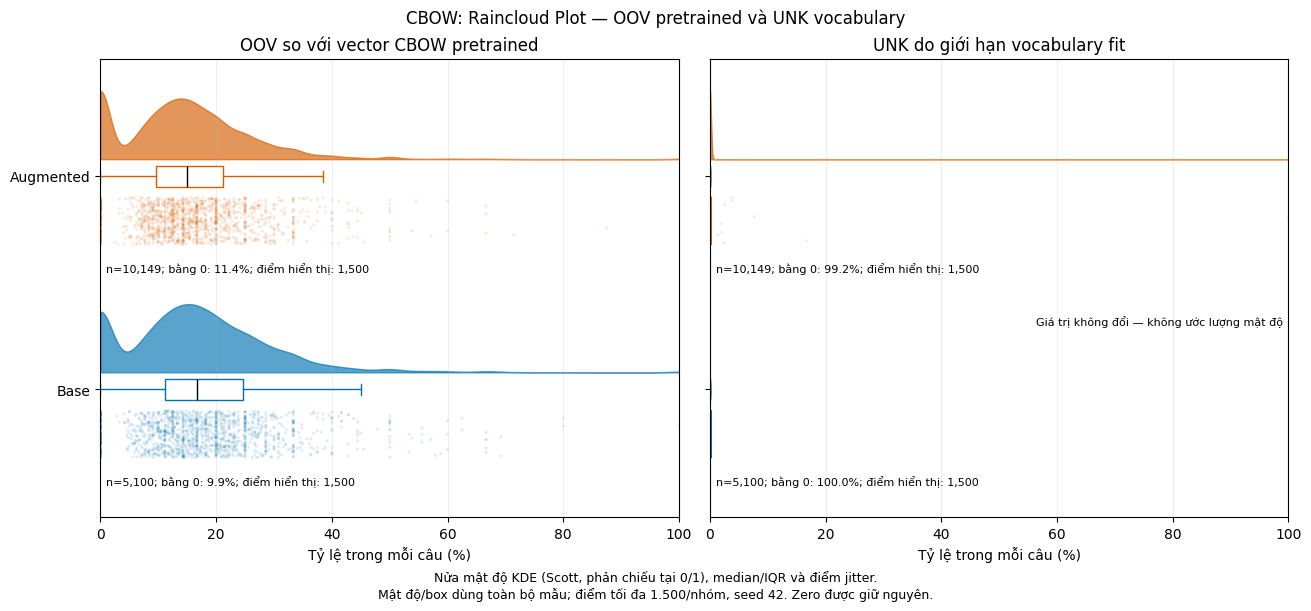

In [ ]:
def plot_cbow_raincloud(samples, out_dir):
    """Full-data reflected KDE/box summaries; deterministic display-only point sample."""
    from scipy.stats import gaussian_kde
    rng = np.random.default_rng(42)
    summary = []
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True, layout='constrained')
    grid = np.linspace(0., 1., 501)
    colors = ['#0072B2', '#D55E00']
    for ax, field, title in zip(axes, ['pretrained_oov_fraction', 'vocab_unk_fraction'], ['OOV so với vector CBOW pretrained', 'UNK do giới hạn vocabulary fit']):
        for y, dataset in enumerate(['Base', 'Augmented']):
            values = samples.loc[samples.dataset == dataset, field].to_numpy(dtype=float)
            if len(values) == 0 or not np.isfinite(values).all() or not ((values >= 0) & (values <= 1)).all():
                raise ValueError(f'Dữ liệu tỷ lệ không hợp lệ: {dataset}/{field}')
            color = colors[y]
            if len(values) > 1 and np.ptp(values) > 1e-12:
                kde = gaussian_kde(values, bw_method='scott')
                density = kde(grid) + kde(-grid) + kde(2-grid)
                density /= np.trapezoid(density, grid)
                ax.fill_between(100*grid, y+.08, y+.08+.32*density/density.max(), color=color, alpha=.65)
            else:
                ax.text(99, y+.30, 'Giá trị không đổi — không ước lượng mật độ', ha='right', fontsize=8)
            ax.boxplot([100*values], positions=[y], widths=.10, vert=False, showfliers=False,
                       patch_artist=True, boxprops={'facecolor':'white','edgecolor':color},
                       medianprops={'color':'black'}, whiskerprops={'color':color}, capprops={'color':color})
            shown = rng.choice(len(values), min(1500,len(values)), replace=False)
            ax.scatter(100*values[shown], y-rng.uniform(.10,.32,len(shown)), s=5, color=color, alpha=.12, edgecolors='none', rasterized=True)
            q1, median, q3 = np.quantile(values,[.25,.5,.75])
            zero = np.mean(values==0)
            ax.text(1, y-.45, f'n={len(values):,}; bằng 0: {100*zero:.1f}%; điểm hiển thị: {len(shown):,}', fontsize=8)
            summary.append(dict(metric=field,dataset=dataset,n=len(values),display_points=len(shown),zero_fraction=float(zero),q1=float(q1),median=float(median),q3=float(q3)))
        ax.set(xlim=(0,100),ylim=(-.6,1.55),yticks=[0,1],yticklabels=['Base','Augmented'],xlabel='Tỷ lệ trong mỗi câu (%)',title=title)
        ax.grid(axis='x',alpha=.2)
    fig.suptitle('CBOW: Raincloud Plot — OOV pretrained và UNK vocabulary')
    fig.supxlabel('Nửa mật độ KDE (Scott, phản chiếu tại 0/1), median/IQR và điểm jitter.\nMật độ/box dùng toàn bộ mẫu; điểm tối đa 1.500/nhóm, seed 42. Zero được giữ nguyên.',fontsize=9)
    out_dir = Path(out_dir); out_dir.mkdir(parents=True,exist_ok=True)
    fig.savefig(out_dir/'cbow-coverage.png',dpi=160)
    pd.DataFrame(summary).to_csv(out_dir/'cbow-raincloud-summary.csv',index=False)
    plt.show(); plt.close(fig)
    return pd.DataFrame(summary)

raincloud_summary = plot_cbow_raincloud(samples, OUT)
display(raincloud_summary)
import zipfile, platform
manifest={'dataset':DATASET_HANDLE,'cpu_only':True,'test_usage':'schema and text overlap only','sources':{name:hashlib.sha256(path.read_bytes()).hexdigest() for name,path in paths.items()},'python':platform.python_version()}
(OUT/'source.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
with zipfile.ZipFile('/content/vlsp-eda-complete.zip','w',zipfile.ZIP_DEFLATED) as archive:
    for path in OUT.iterdir():
        if path.is_file():archive.write(path,path.name)
print('EDA_COMPLETE',OUT.resolve())


## Kết luận EDA và quyết định trước huấn luyện

| Quan sát / bằng chứng CPU | Quyết định | Giới hạn |
|---|---|---|
| NFC/khoảng trắng thay đổi 213/5.100 câu Base và 1/10.149 câu Augmented; không tạo câu rỗng hoặc nhóm va chạm mới | Chuẩn NFC/khoảng trắng, giữ văn bản gốc | Soát lại trùng/giao tập sau xử lý; không suy chất lượng nhãn từ tần suất |
| TF-IDF word+emoticon: 5.000 đặc trưng giữ 60,35%/63,78% lượt đặc trưng-văn bản Base/Augmented; 20.000 giữ 76,07%/78,52%; câu mất hết đặc trưng giảm 4→2 và 9→3 | Chữ thường; unigram/bigram; giữ emoticon bằng analyzer đã khảo sát; max_features=20.000, min_df=1, sparse float32 và dense theo minibatch | Coverage đo trên chính tập fit, không phải tổng số token hoặc bảo đảm tăng F1; batch 128 dense khoảng 10,24 MB, chưa gồm activation CNN |
| CBOW ở 300 từ cắt 16/5.100 câu Base, 27/10.149 câu Augmented; mất 5,66%/3,16% lượt token vì có đuôi dài | Giữ giới hạn 300, PyVi sau chữ thường; vocabulary 10.000 fit riêng, PAD/UNK, embedding trainable độc lập | Tỷ lệ câu bị cắt nhỏ không có nghĩa lượng nội dung mất nhỏ; OOV pretrained khác UNK vocabulary |
| PhoBERT 256 token cắt 22 câu Base và 36 câu Augmented, mất 6,10%/3,76% lượt token; chữ thường làm tổng BPE tăng 172.312→174.840 và 328.094→331.324 | Giữ hoa/thường, RDRSegmenter trước BPE, giới hạn 256 gồm token đặc biệt | Giới hạn kiến trúc; không loại câu dài để làm đẹp chỉ số |
| Thay teencode chỉ giảm OOV CBOW Base từ 27.373 xuống 27.360; emoticon xuất hiện ở cả ba lớp, ngữ cảnh có thể mỉa mai | Không thay đồng loạt teencode/emoticon bằng từ có nghĩa định sẵn; không rút chữ kéo dài hoặc xóa ký hiệu | Không khẳng định các quy tắc này luôn có hại; muốn kết luận về F1 cần thí nghiệm validation riêng |

Các lựa chọn được chốt từ Base/Augmented và chi phí biểu diễn, trước khi đo kết quả mô hình mới. Không dùng nhãn test hoặc điểm test để chọn xử lý. Từng quy tắc ứng viên trong bảng tác động đều được áp dụng cùng nền NFC/khoảng trắng; số dòng thay đổi được so với dữ liệu gốc, các nhóm không cộng được với nhau.
